# Recommending Steam Games: Popularity vs. Collaborative Filtering vs. Linear Autoencoders

**Task.** Given the games a Steam user has *played*, rank the rest of the catalog so that the game they actually play next (held-out) appears near the top.

**Contributions of this notebook**
1. A leakage-free **train / validation / test** protocol with **full-catalog ranking** (no sampled negatives) and bootstrap confidence intervals.
2. Seven recommenders, from trivial baselines to modern linear models: Random, Popularity, Item-kNN, PureSVD, implicit ALS (binary and playtime-weighted), BPR-MF, and EASE.
3. Error analysis beyond one number: by user activity, by held-out-game popularity, catalog coverage / exposure inequality, hyper-parameter sensitivity, learned embeddings, and a qualitative case study.

**Notebook map (matches the five graded presentation sections)**

| Section | Content |
|---|---|
| 1 | Predictive task, evaluation, baselines, validity |
| 2 | Data, exploratory analysis, pre-processing |
| 3 | Modeling |
| 4 | Evaluation, ablations, error analysis |
| 5 | Related work and conclusion |

# 1. Predictive task

**Task.** *Top-N implicit-feedback recommendation.* For each user $u$ with played-game set $I_u$, produce a ranked list over all games $u$ has not played. One played game per user is hidden; the model is judged on where that game lands in the ranking.

**Why this formulation?** The Steam data has no star ratings. We observe *what* a user owns and *how long* they played it, so "played" is the implicit positive signal. Ranking, not rating prediction, is what a store front actually needs.

**Evaluation protocol**
- Per user: 1 test game, 1 validation game, the rest for training. Models are tuned on validation only. The final models are refit on train+validation and scored once on test.
- Every model ranks **all** unseen games (full ranking). Sampled-negative evaluation is known to distort model comparisons (Krichene & Rendle, 2020).
- Because each user has exactly one relevant item, **Recall@K = HitRate@K**, and Precision@K is just Recall@K / K. Precision adds nothing, so we report: **HR@10, NDCG@10, MRR, and AUC (mean percentile rank)**, each with a 95% bootstrap CI over users.
- Ties are resolved pessimistically (a game tied with the target counts as ranked above it), so a model cannot gain by outputting many identical scores.

**Baselines**
- *Random*: sanity check. Its HR@10 must match the theoretical value 10 / (number of candidate games).
- *Popularity*: the standard non-personalized baseline; very strong on long-tailed data.
- *Item-kNN* and *PureSVD*: the neighborhood and latent-factor methods covered in class.

**Validity checks**
1. Random must be at chance.
2. A personalized model must beat Popularity with a CI that excludes 0 on paired differences.
3. Gains must hold across user-activity buckets, not only for heavy users.
4. We report coverage and exposure concentration to show accuracy is not bought by recommending only blockbusters.

**Caveat.** This is an *offline proxy*. A held-out played game is not proof the user would *prefer* it over other recommendations, and the data has no timestamps, so the split is random rather than temporal.

# 2. Data, exploratory analysis, and pre-processing

## 2.1 Context: where the data comes from
**Source:** UCSD McAuley Lab, *Steam Video Game and Bundle Data* ([dataset page](https://mcauleylab.ucsd.edu/public_datasets/data/datasets.html)). We use the **Australian users and their items** file: one record per public Steam profile with the list of games owned and `playtime_forever` (minutes) for each. The profile crawl originates from O'Neill et al. (IMC 2016), as credited on the dataset page.

**Format gotcha.** Each line of the file is a *Python dict literal* (single quotes), **not strict JSON**. `json.loads` raises `JSONDecodeError` on it; the loader below falls back to `ast.literal_eval`.

**Sampling.** Parsing every user is slow and the dense item-item matrices need memory, so we keep a **random** fraction of users (`SAMPLE_FRAC`). The original notebook took the *first N lines*, which is a non-random slice if the file is ordered.

In [1]:
import os, gzip, json, ast, time, itertools, warnings
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
rng = np.random.default_rng(SEED)

# ---------------- experiment configuration ----------------
SAMPLE_FRAC    = 0.35   # fraction of users (random) to load
MIN_PLAYTIME   = 0      # minutes; an interaction counts as "played" if playtime_forever > MIN_PLAYTIME
MIN_USER_ITEMS = 5      # k-core: min played games per user
MIN_ITEM_USERS = 20     # k-core: min players per game
TOP_K          = 10
TUNE_USERS     = 5000   # validation users used for hyper-parameter search
FAST_MODE      = False  # True = tiny grids / fewer iterations (for a quick smoke test)

DATA_DIR  = Path("data"); DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / "australian_users_items.json.gz"
DATA_URL  = "https://mcauleylab.ucsd.edu/public_datasets/data/steam/australian_users_items.json.gz"

if not DATA_PATH.exists():
    print("Downloading Steam user-item data ...")
    urlretrieve(DATA_URL, DATA_PATH)
print(f"{DATA_PATH.resolve()}  ({DATA_PATH.stat().st_size / 2**20:.1f} MB)")

/Users/shirleybianyw/Downloads/data/australian_users_items.json.gz  (70.6 MB)


In [2]:
def parse_line(line):
    # The UCSD Steam files are Python-literal lines, not strict JSON.
    try:
        return json.loads(line)
    except json.JSONDecodeError:
        return ast.literal_eval(line)

records, names = [], {}
n_profiles = n_private = 0
t0 = time.time()
with gzip.open(DATA_PATH, "rt", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        n_profiles += 1
        if rng.random() > SAMPLE_FRAC:          # random user sample; skipped lines are never parsed
            continue
        obj = parse_line(line)
        items = obj.get("items") or []
        if not items:                            # private / empty library
            n_private += 1
            continue
        uid = obj["user_id"]
        for e in items:
            iid = str(e["item_id"])
            names.setdefault(iid, e.get("item_name"))
            records.append((uid, iid, float(e.get("playtime_forever") or 0)))

raw = pd.DataFrame(records, columns=["user_id", "item_id", "playtime"]).drop_duplicates(["user_id", "item_id"])
raw["hours"]  = raw.playtime / 60
raw["played"] = raw.playtime > MIN_PLAYTIME
print(f"Parsed in {time.time()-t0:.0f}s | profiles in file: {n_profiles:,} | sampled with empty library: {n_private:,}")
print(f"Loaded interactions: {len(raw):,} | users: {raw.user_id.nunique():,} | games: {raw.item_id.nunique():,}")
raw.head()

Parsed in 34s | profiles in file: 88,310 | sampled with empty library: 5,877
Loaded interactions: 1,810,138 | users: 24,793 | games: 10,094


,user_id,item_id,playtime,hours,played
0,doctr,300,1131.0,18.850000,True
1,doctr,20,89.0,1.483333,True
2,doctr,50,178.0,2.966667,True
3,doctr,70,108.0,1.800000,True
4,doctr,130,313.0,5.216667,True


## 2.2 Exploratory analysis
Questions the EDA answers, and why each matters for modeling:
- **Is ownership the same as engagement?** If many owned games have zero playtime, treating ownership as a positive would teach models about Steam sales rather than taste.
- **How heavy-tailed are users and games?** Heavy tails make Popularity strong and make some models over-recommend blockbusters.
- **Does popularity predict engagement?** If widely owned games are also played for long, popularity is a legitimately strong signal; if not, the two signals diverge.

,value
Users,"24,793.0000"
Games,"10,094.0000"
"Owned (user, game) pairs","1,810,138.0000"
Played pairs (playtime > threshold),"1,143,484.0000"
Share of owned pairs never played,0.3683
Median games owned per user,40.0000
Median games played per user,28.0000
Matrix density (owned),0.0072
Gini of games' owner counts,0.8401


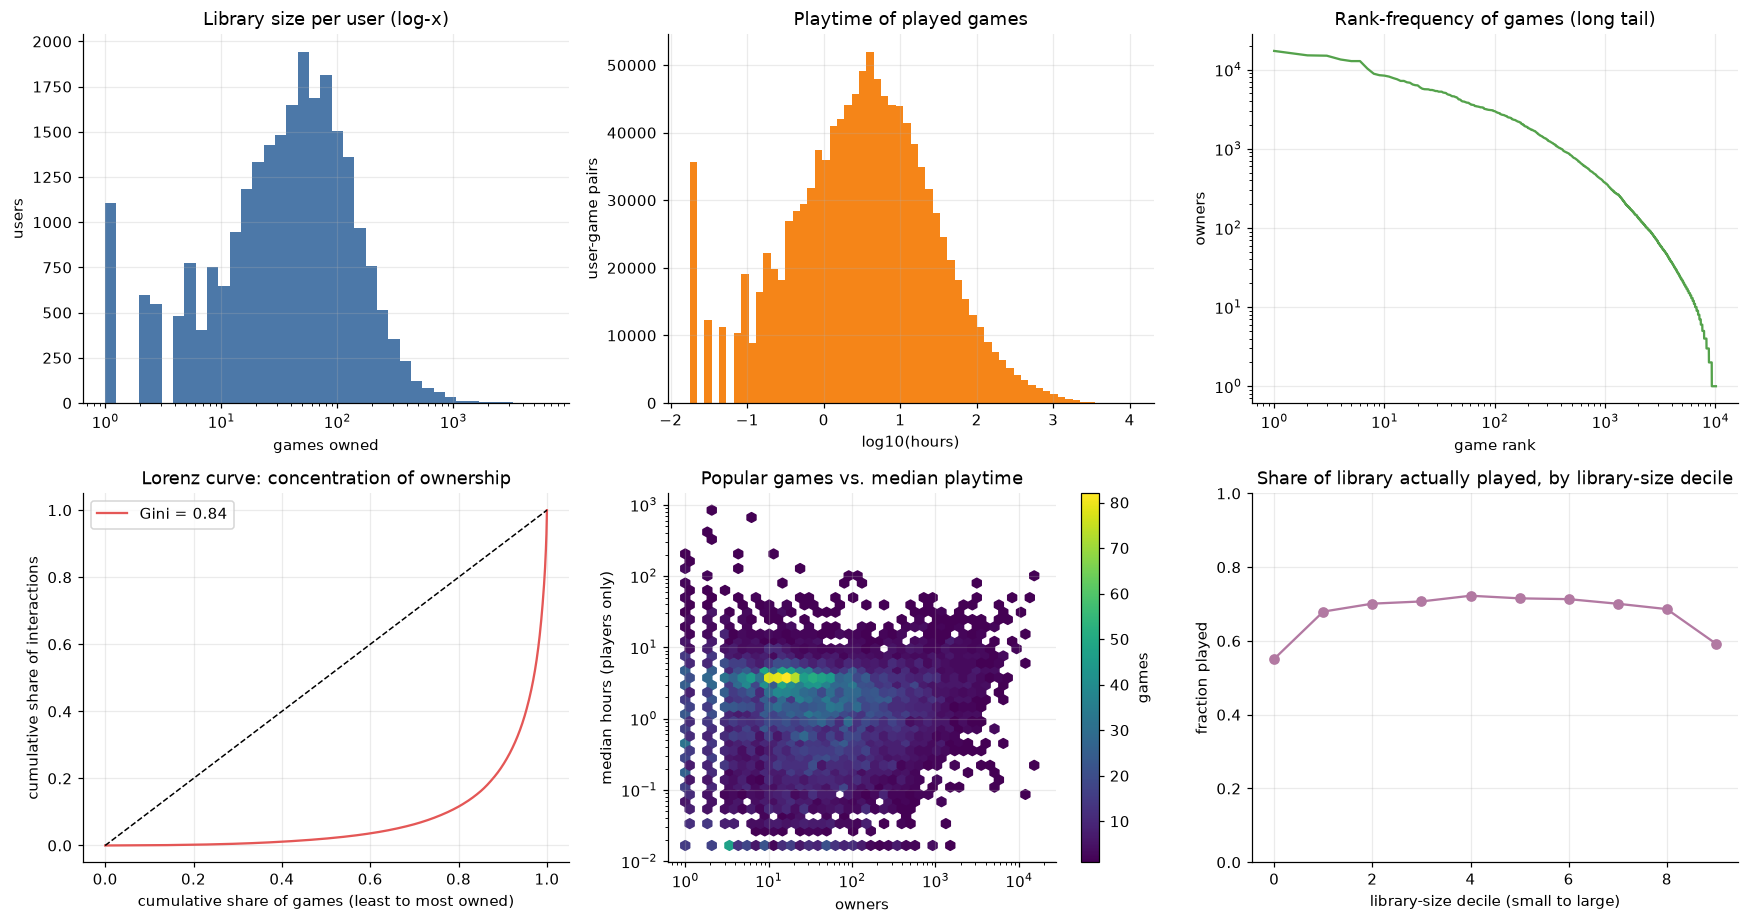

Spearman(owners, median hours played) = 0.012


,most owned,owners,most played (total),hours
0,Dota 2 Test,17249,Counter-Strike: Global Offensive,4557846.0
1,Counter-Strike: Global Offensive,15170,Garry's Mod,2641981.0
2,Garry's Mod,15015,Terraria,921701.0
3,Unturned,13442,The Elder Scrolls V: Skyrim,799927.0
4,Left 4 Dead 2 Beta,12833,Warframe,738088.0
5,Left 4 Dead 2,12833,Counter-Strike: Source,678957.0
6,Terraria,10316,Left 4 Dead 2,614464.0
7,Warframe,8881,PAYDAY 2,579631.0
8,Portal 2,8515,Sid Meier's Civilization V,474616.0
9,Counter-Strike: Source,8404,Rust,462840.0


In [3]:
users_df = raw.groupby("user_id").agg(n_owned=("item_id", "size"), n_played=("played", "sum"))
users_df["frac_played"] = users_df.n_played / users_df.n_owned
items_df = raw.groupby("item_id").agg(owners=("user_id", "size"), players=("played", "sum"), total_hours=("hours", "sum"))
items_df["median_hours_played"] = raw[raw.played].groupby("item_id").hours.median()
items_df["name"] = items_df.index.map(names)

def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x); c = np.cumsum(x)
    return (n + 1 - 2 * c.sum() / c[-1]) / n

summary = pd.Series({
    "Users": users_df.shape[0],
    "Games": items_df.shape[0],
    "Owned (user, game) pairs": len(raw),
    "Played pairs (playtime > threshold)": int(raw.played.sum()),
    "Share of owned pairs never played": 1 - raw.played.mean(),
    "Median games owned per user": users_df.n_owned.median(),
    "Median games played per user": users_df.n_played.median(),
    "Matrix density (owned)": len(raw) / (users_df.shape[0] * items_df.shape[0]),
    "Gini of games' owner counts": gini(items_df.owners),
})
display(summary.to_frame("value").style.format("{:,.4f}"))

fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
ax = ax.ravel()

bins = np.logspace(0, np.log10(users_df.n_owned.max() + 1), 40)
ax[0].hist(users_df.n_owned, bins=bins, color="#4C78A8"); ax[0].set(xscale="log", title="Library size per user (log-x)", xlabel="games owned", ylabel="users")

ax[1].hist(np.log10(raw.loc[raw.played, "hours"] + 1e-3), bins=60, color="#F58518")
ax[1].set(title="Playtime of played games", xlabel="log10(hours)", ylabel="user-game pairs")

ranked = np.sort(items_df.owners.values)[::-1]
ax[2].loglog(np.arange(1, len(ranked) + 1), ranked, color="#54A24B")
ax[2].set(title="Rank-frequency of games (long tail)", xlabel="game rank", ylabel="owners")

cum = np.cumsum(np.sort(items_df.owners.values)); cum = np.r_[0, cum / cum[-1]]
ax[3].plot(np.linspace(0, 1, len(cum)), cum, color="#E45756", label=f"Gini = {gini(items_df.owners):.2f}")
ax[3].plot([0, 1], [0, 1], "k--", lw=1); ax[3].legend()
ax[3].set(title="Lorenz curve: concentration of ownership", xlabel="cumulative share of games (least to most owned)", ylabel="cumulative share of interactions")

ok = items_df.median_hours_played.notna()
hb = ax[4].hexbin(items_df.owners[ok], items_df.median_hours_played[ok], xscale="log", yscale="log", gridsize=40, mincnt=1, cmap="viridis")
ax[4].set(title="Popular games vs. median playtime", xlabel="owners", ylabel="median hours (players only)")
fig.colorbar(hb, ax=ax[4], label="games")

q = pd.qcut(users_df.n_owned, 10, duplicates="drop")
g = users_df.groupby(q, observed=True).frac_played.mean()
ax[5].plot(range(len(g)), g.values, "o-", color="#B279A2")
ax[5].set(title="Share of library actually played, by library-size decile", xlabel="library-size decile (small to large)", ylabel="fraction played", ylim=(0, 1))

plt.tight_layout(); plt.show()

corr = items_df.loc[ok, ["owners", "median_hours_played"]].rank().corr().iloc[0, 1]
print(f"Spearman(owners, median hours played) = {corr:.3f}")

top = pd.concat([
    items_df.nlargest(10, "owners")[["name", "owners"]].reset_index(drop=True),
    items_df.nlargest(10, "total_hours")[["name", "total_hours"]].round(0).reset_index(drop=True)], axis=1)
top.columns = ["most owned", "owners", "most played (total)", "hours"]
display(top)

**What the EDA tells us (read against the plots above).**
- The never-played share and its trend across library-size deciles show that **ownership is a noisy proxy for interest**, especially for users with huge libraries (typically bundle and sale purchases). We therefore define a positive as **playtime > threshold**, not ownership.
- The rank-frequency plot and the Lorenz/Gini values show a pronounced long tail: a few games hold a large share of interactions. Popularity will be hard to beat on *head* items, so Section 4 stratifies the results by head/torso/tail.
- The owners-vs-median-hours panel shows whether popularity and engagement agree. Free-to-play titles tend to be owned by many people who play briefly, so "owned by many" is not the same as "played for long."

## 2.3 Pre-processing
1. **Positive interaction** = `playtime_forever > MIN_PLAYTIME`.
2. **Iterative k-core filter** (repeat until stable): users with at least `MIN_USER_ITEMS` played games and games with at least `MIN_ITEM_USERS` players. (The original draft ran a fixed 3 passes, which does not guarantee a stable core.)
3. **Per-user random split**: 1 test game, 1 validation game, rest train. All users have at least 5 interactions after filtering, so everyone has all three parts. The split is vectorized and seeded.
4. Two training matrices: **binary** (played = 1) and **playtime-weighted** (`log(1 + hours)`), the latter used by one ALS variant to test whether engagement strength helps.

In [4]:
def kcore(df, min_u, min_i):
    while True:
        n0 = len(df)
        df = df[df.groupby("user_id").item_id.transform("size") >= min_u]
        df = df[df.groupby("item_id").user_id.transform("size") >= min_i]
        if len(df) == n0:
            return df

pos = kcore(raw[raw.played][["user_id", "item_id", "hours"]], MIN_USER_ITEMS, MIN_ITEM_USERS).copy()
pos["u"], user_ids = pd.factorize(pos.user_id)
pos["i"], item_ids = pd.factorize(pos.item_id)
n_users, n_items = len(user_ids), len(item_ids)
item_names = np.array([names.get(i) or f"App {i}" for i in item_ids])

# per-user random order -> rank 1 = test, 2 = validation, >=3 = train
pos["rnd"] = rng.random(len(pos))
pos["rk"]  = pos.groupby("u").rnd.rank(method="first")
train, val, test = pos[pos.rk > 2], pos[pos.rk == 2], pos[pos.rk == 1]
test_item = np.zeros(n_users, int); test_item[test.u.values] = test.i.values
val_item  = np.zeros(n_users, int); val_item[val.u.values]   = val.i.values

def build(df, weighted=False):
    v = np.log1p(df.hours.values) if weighted else np.ones(len(df))
    return csr_matrix((v.astype(np.float32), (df.u.values, df.i.values)), shape=(n_users, n_items))

trval = pd.concat([train, val])
X_train, W_train = build(train), build(train, True)      # used for tuning
X_trval, W_trval = build(trval), build(trval, True)      # used for the final fit / test
all_users = np.arange(n_users)

cold = (np.asarray(X_trval.sum(0)).ravel()[test_item] == 0).mean()
display(pd.Series({
    "Users": n_users, "Games": n_items,
    "Train interactions": len(train), "Validation interactions": len(val), "Test interactions": len(test),
    "Density (train)": X_train.nnz / (n_users * n_items),
    "Test games with zero train+val players (unrecoverable)": cold,
}).to_frame("value").style.format("{:,.5f}"))

,value
Users,"20,940.00000"
Games,"3,570.00000"
Train interactions,"1,063,175.00000"
Validation interactions,"20,940.00000"
Test interactions,"20,940.00000"
Density (train),0.01422
Test games with zero train+val players (unrecoverable),0.00000


# 3. Modeling

## 3.1 Formulation
- **Input:** binary user-game matrix $X \in \{0,1\}^{U \times I}$ (optionally weighted by $\log(1+\text{hours})$).
- **Output:** a score $\hat{s}_{ui}$ for every game; recommendations are the top-$K$ unseen games by score.
- **Optimized:** depends on the model. Reconstruction error (PureSVD, EASE), weighted squared error with confidence (ALS), or pairwise ranking likelihood (BPR).

## 3.2 Models and trade-offs

| Model | Idea | Pros | Cons |
|---|---|---|---|
| Random | uniform scores | sanity check | none |
| Popularity | score = number of players | trivial, strong on long-tailed data | not personalized; zero coverage of the tail |
| Item-kNN | $s_{ui}=\sum_{j\in I_u} \mathrm{sim}(j,i)$, asymmetric cosine with top-$k$ neighbors | interpretable, no training | dense $I\times I$ matrix; sensitive to popularity normalization $\alpha$ |
| PureSVD | project the user row onto top-$f$ singular vectors | one SVD call, fast | first component mostly encodes popularity; treats unobserved as 0 |
| Implicit ALS | latent factors with confidence $c_{ui}=1+\alpha r_{ui}$ over *all* cells (Hu, Koren & Volinsky 2008) | principled for implicit data; closed-form updates | slower; $\alpha$, reg, $f$ to tune |
| BPR-MF | maximize $\ln\sigma(\hat{s}_{ui}-\hat{s}_{uj})$ for observed $i$, sampled unobserved $j$ (Rendle et al. 2009) | optimizes ranking directly | negative sampling noise; learning-rate sensitive |
| EASE | closed-form linear autoencoder $B$ with zero diagonal (Steck 2019) | no SGD; often state of the art on sparse data | $O(I^3)$ inverse and $I^2$ memory: does not scale to millions of items |

All models implement the same interface (`fit(X, W)` and `score(users)`), so one evaluation routine scores them all. Everything is implemented from scratch in NumPy/SciPy except the truncated SVD solver.

In [5]:
# ---------- shared utilities ----------
_gram_cache = {"key": None, "G": None}
def gram(X):
    # Item-item co-occurrence X^T X, computed with dense BLAS blocks and cached (shared by Item-kNN and EASE).
    key = (id(X), X.nnz)
    if _gram_cache["key"] != key:
        n = X.shape[1]; G = np.zeros((n, n), np.float32)
        for s in range(0, X.shape[0], 4000):
            blk = X[s:s + 4000].toarray().astype(np.float32)
            G += blk.T @ blk
        _gram_cache.update(key=key, G=G)
    return _gram_cache["G"]

def scatter_mean_update(M, idx, upd, lr):
    # M[idx] += lr * mean(upd over duplicate idx). Vectorised stand-in for np.add.at; averaging keeps hot items stable.
    order = np.argsort(idx, kind="stable"); s = idx[order]
    starts = np.flatnonzero(np.r_[True, s[1:] != s[:-1]])
    agg = np.add.reduceat(upd[order], starts, axis=0)
    cnt = np.diff(np.r_[starts, len(s)])
    M[s[starts]] += lr * agg / (cnt[:, None] if agg.ndim == 2 else cnt)

# ---------- models ----------
class Random:
    def fit(self, X, W=None): self.n = X.shape[1]; self.r = np.random.default_rng(SEED); return self
    def score(self, u): return self.r.random((len(u), self.n), dtype=np.float32)

class Popularity:
    def fit(self, X, W=None): self.pop = np.asarray(X.sum(0)).ravel().astype(np.float32); return self
    def score(self, u): return np.tile(self.pop, (len(u), 1))

class ItemKNN:
    # score(u,j) = sum_{i in I_u} S[i,j],  S[i,j] = co(i,j) / (n_i^alpha * n_j^(1-alpha)),  top-k neighbours per i (alpha=.5 is cosine)
    def __init__(self, k=100, alpha=0.5): self.k, self.alpha = k, alpha
    def fit(self, X, W=None):
        n = X.shape[1]; co = gram(X); cnt = np.maximum(np.asarray(X.sum(0)).ravel(), 1).astype(np.float32)
        d1, d2 = cnt ** self.alpha, cnt ** (1 - self.alpha)
        k = min(self.k, n - 2); R, C, V = [], [], []
        for s in range(0, n, 1000):
            blk = co[s:s + 1000] / (d1[s:s + 1000, None] * d2[None, :])
            blk[np.arange(blk.shape[0]), np.arange(s, s + blk.shape[0])] = 0          # no self-similarity
            idx = np.argpartition(-blk, k, axis=1)[:, :k]
            R.append(np.repeat(np.arange(s, s + blk.shape[0]), k)); C.append(idx.ravel()); V.append(np.take_along_axis(blk, idx, 1).ravel())
        self.S = csr_matrix((np.concatenate(V), (np.concatenate(R), np.concatenate(C))), shape=(n, n)); self.X = X
        return self
    def score(self, u): return (self.X[u] @ self.S).toarray()

class PureSVD:
    def __init__(self, f=64): self.f = f
    def fit(self, X, W=None):
        self.svd = TruncatedSVD(self.f, n_iter=7, random_state=SEED).fit(X)
        self.V = self.svd.components_.astype(np.float32); self.X = X; return self
    def score(self, u): return (self.X[u] @ self.V.T) @ self.V

class ImplicitALS:
    # Hu-Koren-Volinsky: minimise sum_{u,i} c_ui (p_ui - x_u.y_i)^2 + reg(|x|^2+|y|^2), c_ui = 1 + alpha*r_ui, p_ui = 1[observed]
    def __init__(self, f=64, alpha=20.0, reg=10.0, iters=10, weighted=False):
        self.f, self.alpha, self.reg, self.iters, self.weighted = f, alpha, reg, iters, weighted
    def _solve(self, R, Y):
        YtY = (Y.T @ Y).astype(np.float64) + self.reg * np.eye(self.f)
        out = np.zeros((R.shape[0], self.f), np.float32); ind, ptr, dat = R.indices, R.indptr, R.data
        for u in range(R.shape[0]):
            s, e = ptr[u], ptr[u + 1]
            if s == e: continue
            Yi = Y[ind[s:e]].astype(np.float64); r = dat[s:e].astype(np.float64)
            A = YtY + (Yi.T * (self.alpha * r)) @ Yi
            out[u] = np.linalg.solve(A, (1 + self.alpha * r) @ Yi)
        return out
    def fit(self, X, W=None):
        R = (W if (self.weighted and W is not None) else X).tocsr(); Rt = R.T.tocsr()
        r = np.random.default_rng(SEED); self.Y = r.normal(0, .01, (X.shape[1], self.f)).astype(np.float32)
        for _ in range(self.iters):
            self.U = self._solve(R, self.Y); self.Y = self._solve(Rt, self.U)
        return self
    def score(self, u): return self.U[u] @ self.Y.T

class BPRMF:
    def __init__(self, f=64, lr=0.1, reg=0.01, epochs=20, batch=2048): self.f, self.lr, self.reg, self.epochs, self.batch = f, lr, reg, epochs, batch
    def fit(self, X, W=None):
        r = np.random.default_rng(SEED); n_u, n_i = X.shape; Xc = X.tocsr(); coo = X.tocoo()
        us, its = coo.row.astype(np.int64), coo.col.astype(np.int64)
        self.P = r.normal(0, .1, (n_u, self.f)).astype(np.float32); self.Q = r.normal(0, .1, (n_i, self.f)).astype(np.float32); self.b = np.zeros(n_i, np.float32)
        for _ in range(self.epochs):
            perm = r.permutation(len(us))
            for s in range(0, len(us), self.batch):
                sel = perm[s:s + self.batch]; u, i = us[sel], its[sel]
                j = r.integers(0, n_i, len(sel))
                bad = np.asarray(Xc[u, j]).ravel() > 0                      # resample negatives that are actually positives
                if bad.any(): j[bad] = r.integers(0, n_i, bad.sum())
                pu, qi, qj = self.P[u], self.Q[i], self.Q[j]
                x = (pu * (qi - qj)).sum(1) + self.b[i] - self.b[j]
                g = (1 / (1 + np.exp(np.clip(x, -30, 30)))).astype(np.float32)[:, None]   # sigma(-x)
                scatter_mean_update(self.P, u, g * (qi - qj) - self.reg * pu, self.lr)
                scatter_mean_update(self.Q, i, g * pu - self.reg * qi, self.lr)
                scatter_mean_update(self.Q, j, -g * pu - self.reg * qj, self.lr)
                scatter_mean_update(self.b, i, g[:, 0] - self.reg * self.b[i], self.lr)
                scatter_mean_update(self.b, j, -g[:, 0] - self.reg * self.b[j], self.lr)
        return self
    def score(self, u): return self.P[u] @ self.Q.T + self.b

class EASE:
    # Steck (2019): B = argmin ||X - XB||^2 + lam||B||^2  s.t. diag(B)=0  ->  B_ij = -P_ij / P_jj, P = (X^T X + lam I)^-1
    def __init__(self, lam=500.0): self.lam = lam
    def fit(self, X, W=None):
        G = gram(X).astype(np.float64); G[np.diag_indices_from(G)] += self.lam
        P = np.linalg.inv(G); B = -P / np.diag(P)[None, :]; np.fill_diagonal(B, 0.0)
        self.B = B.astype(np.float32); self.X = X; return self
    def score(self, u): return np.asarray(self.X[u] @ self.B)

# 4. Evaluation

## 4.1 Protocol implementation
`rank_of_targets` scores a batch of users against the **entire catalog**, masks games the user already has, and returns the (pessimistic) rank of the held-out game. All metrics derive from that single rank, so they are guaranteed consistent:

- $\text{HR@K}=\mathbb{1}[\text{rank}\le K]$, $\text{NDCG@K}=\mathbb{1}[\text{rank}\le K]/\log_2(\text{rank}+1)$ (ideal DCG is 1 with one relevant item), $\text{MRR}=1/\text{rank}$, $\text{AUC}=1-\frac{\text{rank}-1}{|\text{candidates}|-1}$.

HR@K tells us whether the item is shown at all, NDCG/MRR reward ranking it higher, and AUC summarizes the whole ranking (it is insensitive to the top of the list, so it can disagree with HR@10; both are reported).

In [6]:
def rank_of_targets(model, X_seen, targets, users, batch=2000):
    # Pessimistic rank (1 = best) of targets[u] among all games not in X_seen[u].
    ranks = np.empty(len(users), np.int64)
    for s in range(0, len(users), batch):
        ub = users[s:s + batch]
        sc = np.array(model.score(ub), dtype=np.float32)               # copy: we mutate it below
        r, c = X_seen[ub].nonzero(); sc[r, c] = -np.inf                # remove already-owned games
        t = sc[np.arange(len(ub)), targets[ub]][:, None]
        ranks[s:s + len(ub)] = (sc > t).sum(1) + (sc == t).sum(1)      # = 1 + #strictly-better + #ties
    return ranks

def metrics_from_ranks(ranks, n_cand, K=TOP_K):
    hit = ranks <= K
    return {"HR": hit.astype(float), "NDCG": np.where(hit, 1 / np.log2(ranks + 1.0), 0.0),
            "MRR": 1.0 / ranks, "AUC": 1 - (ranks - 1) / (n_cand - 1)}

def recommend(model, X_seen, users, k=TOP_K, batch=2000):
    out = []
    for s in range(0, len(users), batch):
        ub = users[s:s + batch]; sc = np.array(model.score(ub), dtype=np.float32)
        r, c = X_seen[ub].nonzero(); sc[r, c] = -np.inf
        idx = np.argpartition(-sc, k, axis=1)[:, :k]
        out.append(np.take_along_axis(idx, np.argsort(-np.take_along_axis(sc, idx, 1), axis=1), 1))
    return np.vstack(out)

ncand_val  = n_items - np.diff(X_train.indptr)
ncand_test = n_items - np.diff(X_trval.indptr)
print("Expected Random HR@10 on test:", np.mean(TOP_K / ncand_test).round(5))

Expected Random HR@10 on test: 0.00284


## 4.2 Hyper-parameter tuning (validation only)
Each model family is tuned on a random subset of **validation** users, fitted on the training matrix only, selecting by validation **NDCG@10**. The test set is not touched here. The model factory below is also reused for the final refit.

Item-kNN                  k=50, alpha=0.3                  NDCG@10=0.1229  (2s)
Item-kNN                  k=50, alpha=0.5                  NDCG@10=0.1349  (0s)
Item-kNN                  k=50, alpha=0.7                  NDCG@10=0.1327  (0s)
Item-kNN                  k=200, alpha=0.3                 NDCG@10=0.1233  (1s)
Item-kNN                  k=200, alpha=0.5                 NDCG@10=0.1413  (1s)
Item-kNN                  k=200, alpha=0.7                 NDCG@10=0.1353  (0s)
PureSVD                   f=16                             NDCG@10=0.1575  (1s)
PureSVD                   f=32                             NDCG@10=0.1246  (2s)
PureSVD                   f=64                             NDCG@10=0.1056  (4s)
PureSVD                   f=128                            NDCG@10=0.0913  (8s)
ALS (binary)              f=32, alpha=10, reg=10           NDCG@10=0.1569  (13s)
ALS (binary)              f=32, alpha=40, reg=10           NDCG@10=0.1248  (13s)
ALS (binary)              f=64, alpha=

,model,params,val NDCG@10,val HR@10,fit+eval s
10,ALS (binary),"f=32, alpha=10, reg=10",0.1569,0.2736,13
12,ALS (binary),"f=64, alpha=10, reg=10",0.1537,0.2730,47
11,ALS (binary),"f=32, alpha=40, reg=10",0.1248,0.2316,13
13,ALS (binary),"f=64, alpha=40, reg=10",0.1235,0.2300,50
14,ALS (playtime-weighted),"f=32, alpha=5, reg=10",0.1497,0.2616,13
16,ALS (playtime-weighted),"f=64, alpha=5, reg=10",0.1462,0.2550,49
17,ALS (playtime-weighted),"f=64, alpha=20, reg=10",0.1291,0.2364,47
15,ALS (playtime-weighted),"f=32, alpha=20, reg=10",0.1277,0.2310,13
20,BPR-MF,"f=64, lr=0.05",0.1297,0.2250,57
18,BPR-MF,"f=32, lr=0.05",0.1276,0.2158,34


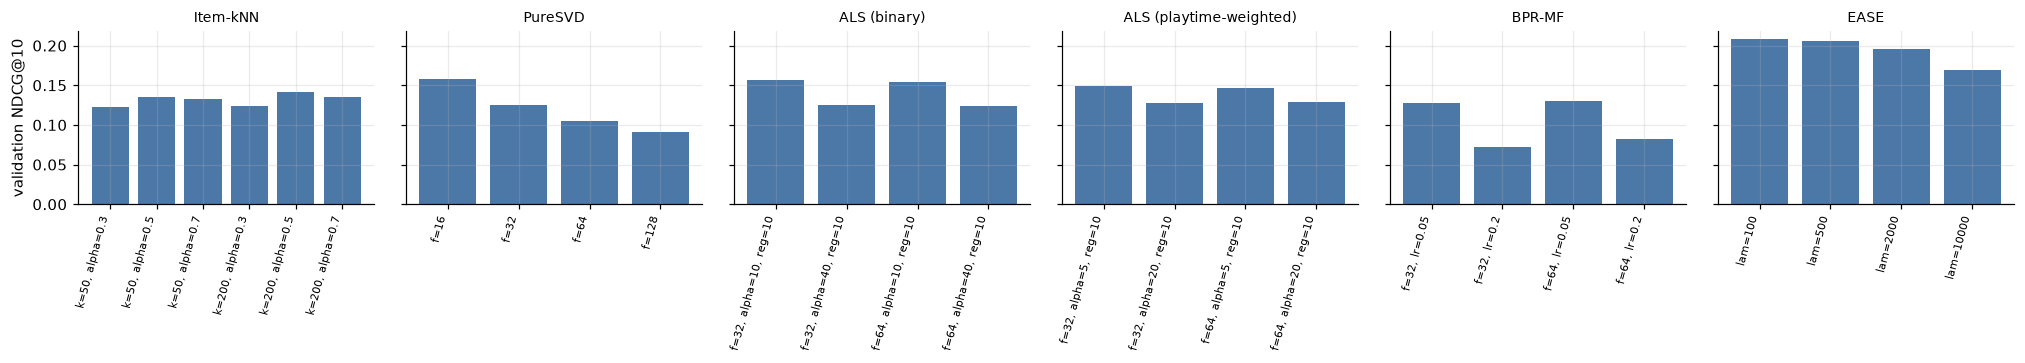

Selected hyper-parameters: {'Item-kNN': {'k': 200, 'alpha': 0.5}, 'PureSVD': {'f': 16}, 'ALS (binary)': {'f': 32, 'alpha': 10, 'reg': 10.0}, 'ALS (playtime-weighted)': {'f': 32, 'alpha': 5, 'reg': 10.0}, 'BPR-MF': {'f': 64, 'lr': 0.05}, 'EASE': {'lam': 100.0}}


In [7]:
FACTORY = {
    "Random":                  lambda **p: Random(),
    "Popularity":              lambda **p: Popularity(),
    "Item-kNN":                lambda **p: ItemKNN(**p),
    "PureSVD":                 lambda **p: PureSVD(**p),
    "ALS (binary)":            lambda **p: ImplicitALS(weighted=False, iters=5 if FAST_MODE else 10, **p),
    "ALS (playtime-weighted)": lambda **p: ImplicitALS(weighted=True,  iters=5 if FAST_MODE else 10, **p),
    "BPR-MF":                  lambda **p: BPRMF(epochs=5 if FAST_MODE else 20, **p),
    "EASE":                    lambda **p: EASE(**p),
}
GRIDS = {
    "Item-kNN":                dict(k=[50, 200], alpha=[0.3, 0.5, 0.7]),
    "PureSVD":                 dict(f=[16, 32, 64, 128]),
    "ALS (binary)":            dict(f=[32, 64], alpha=[10, 40], reg=[10.0]),
    "ALS (playtime-weighted)": dict(f=[32, 64], alpha=[5, 20], reg=[10.0]),
    "BPR-MF":                  dict(f=[32, 64], lr=[0.05, 0.2]),
    "EASE":                    dict(lam=[100.0, 500.0, 2000.0, 10000.0]),
}
MODEL_ORDER = ["Random", "Popularity", "Item-kNN", "PureSVD", "ALS (binary)", "ALS (playtime-weighted)", "BPR-MF", "EASE"]

tune_users = rng.choice(n_users, min(TUNE_USERS, n_users), replace=False)
tuning_rows, best_params = [], {}
for name, grid in GRIDS.items():
    combos = [dict(zip(grid, v)) for v in itertools.product(*grid.values())]
    if FAST_MODE: combos = combos[:2]
    for p in combos:
        t0 = time.time(); m = FACTORY[name](**p).fit(X_train, W_train)
        rk = rank_of_targets(m, X_train, val_item, tune_users)
        mt = metrics_from_ranks(rk, ncand_val[tune_users])
        tuning_rows.append({"model": name, "params": ", ".join(f"{k}={v:g}" for k, v in p.items()), "_p": p,
                            "val NDCG@10": mt["NDCG"].mean(), "val HR@10": mt["HR"].mean(), "fit+eval s": time.time() - t0})
        print(f"{name:25s} {tuning_rows[-1]['params']:32s} NDCG@10={mt['NDCG'].mean():.4f}  ({time.time()-t0:.0f}s)")
tuning_df = pd.DataFrame(tuning_rows)
for name in GRIDS:
    sub = tuning_df[tuning_df.model == name]; best_params[name] = sub.loc[sub["val NDCG@10"].idxmax(), "_p"]
display(tuning_df.drop(columns="_p").sort_values(["model", "val NDCG@10"], ascending=[True, False]).style.format({"val NDCG@10": "{:.4f}", "val HR@10": "{:.4f}", "fit+eval s": "{:.0f}"}))

fig, axes = plt.subplots(1, len(GRIDS), figsize=(3.1 * len(GRIDS), 3.4), sharey=True)
for a, name in zip(axes, GRIDS):
    sub = tuning_df[tuning_df.model == name]; a.bar(range(len(sub)), sub["val NDCG@10"], color="#4C78A8")
    a.set_xticks(range(len(sub))); a.set_xticklabels(sub.params, rotation=75, ha="right", fontsize=7); a.set_title(name, fontsize=9)
axes[0].set_ylabel("validation NDCG@10"); plt.tight_layout(); plt.show()
print("Selected hyper-parameters:", {k: v for k, v in best_params.items()})

## 4.3 Final test evaluation
Selected configurations are **refit on train + validation** and scored on the **test** game of every user. We add a **user-level bootstrap** (resample users with replacement, 500 times) for 95% CIs; the same resamples are used for every model, so differences between models are *paired*.

In [8]:
final_models, per_user = {}, {}
for name in MODEL_ORDER:
    t0 = time.time(); m = FACTORY[name](**best_params.get(name, {})).fit(X_trval, W_trval)
    final_models[name] = m
    ranks = rank_of_targets(m, X_trval, test_item, all_users)
    per_user[name] = {**metrics_from_ranks(ranks, ncand_test), "rank": ranks}
    print(f"{name:25s} fitted+scored in {time.time()-t0:.0f}s")

B = 500
boot_idx = [rng.integers(0, n_users, n_users) for _ in range(B)]
boot = {n: {k: np.array([per_user[n][k][ix].mean() for ix in boot_idx]) for k in ("HR", "NDCG", "MRR", "AUC")} for n in MODEL_ORDER}
ci = lambda a: np.percentile(a, [2.5, 97.5])

rows = []
for n in MODEL_ORDER:
    r = {"Model": n}
    for k, lab in [("HR", f"HR@{TOP_K}"), ("NDCG", f"NDCG@{TOP_K}"), ("MRR", "MRR"), ("AUC", "AUC")]:
        r[lab] = per_user[n][k].mean(); r[lab + " 95% CI"] = f"[{ci(boot[n][k])[0]:.4f}, {ci(boot[n][k])[1]:.4f}]"
    rows.append(r)
results = pd.DataFrame(rows)
display(results.style.format({c: "{:.4f}" for c in results.columns if results[c].dtype == float}).background_gradient(subset=[f"NDCG@{TOP_K}"], cmap="Greens"))

Random                    fitted+scored in 1s
Popularity                fitted+scored in 0s
Item-kNN                  fitted+scored in 4s
PureSVD                   fitted+scored in 1s
ALS (binary)              fitted+scored in 14s
ALS (playtime-weighted)   fitted+scored in 14s
BPR-MF                    fitted+scored in 58s
EASE                      fitted+scored in 4s


,Model,HR@10,HR@10 95% CI,NDCG@10,NDCG@10 95% CI,MRR,MRR 95% CI,AUC,AUC 95% CI
0,Random,0.0027,"[0.0019, 0.0035]",0.0012,"[0.0008, 0.0016]",0.0024,"[0.0021, 0.0027]",0.4983,"[0.4945, 0.5021]"
1,Popularity,0.1890,"[0.1833, 0.1941]",0.1165,"[0.1124, 0.1201]",0.1059,"[0.1025, 0.1093]",0.9076,"[0.9056, 0.9096]"
2,Item-kNN,0.2374,"[0.2312, 0.2434]",0.1484,"[0.1441, 0.1524]",0.1337,"[0.1299, 0.1373]",0.8952,"[0.8921, 0.8981]"
3,PureSVD,0.2723,"[0.2666, 0.2783]",0.1679,"[0.1634, 0.1716]",0.1495,"[0.1452, 0.1530]",0.9114,"[0.9087, 0.9140]"
4,ALS (binary),0.2882,"[0.2817, 0.2939]",0.1696,"[0.1657, 0.1734]",0.1484,"[0.1446, 0.1517]",0.9371,"[0.9352, 0.9393]"
5,ALS (playtime-weighted),0.2736,"[0.2671, 0.2796]",0.1586,"[0.1544, 0.1624]",0.1381,"[0.1344, 0.1414]",0.9247,"[0.9224, 0.9269]"
6,BPR-MF,0.2368,"[0.2307, 0.2421]",0.1441,"[0.1403, 0.1479]",0.1306,"[0.1272, 0.1340]",0.9475,"[0.9461, 0.9487]"
7,EASE,0.3483,"[0.3418, 0.3546]",0.2251,"[0.2201, 0.2296]",0.2007,"[0.1962, 0.2050]",0.9094,"[0.9063, 0.9123]"


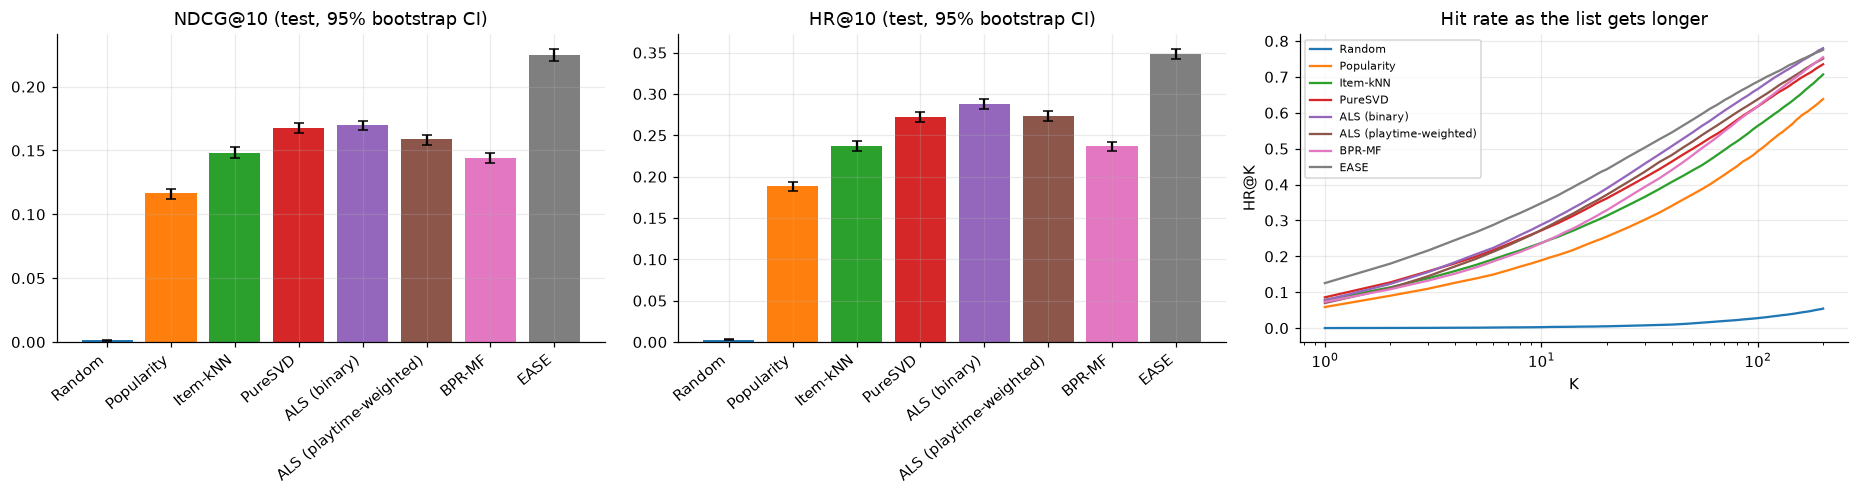

Best model on NDCG@10: EASE


,best vs.,delta NDCG@10,95% CI,excludes 0
0,Random,+0.2239,"[0.2189, 0.2284]",True
1,Popularity,+0.1087,"[0.1047, 0.1130]",True
2,Item-kNN,+0.0767,"[0.0729, 0.0809]",True
3,PureSVD,+0.0572,"[0.0538, 0.0607]",True
4,ALS (binary),+0.0555,"[0.0520, 0.0587]",True
5,ALS (playtime-weighted),+0.0665,"[0.0630, 0.0700]",True
6,BPR-MF,+0.0810,"[0.0770, 0.0850]",True


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(len(MODEL_ORDER)); colors = plt.cm.tab10(np.arange(len(MODEL_ORDER)))
for a, (k, lab) in zip(ax[:2], [("NDCG", f"NDCG@{TOP_K}"), ("HR", f"HR@{TOP_K}")]):
    mu = np.array([per_user[n][k].mean() for n in MODEL_ORDER]); lo = np.array([ci(boot[n][k])[0] for n in MODEL_ORDER]); hi = np.array([ci(boot[n][k])[1] for n in MODEL_ORDER])
    a.bar(x, mu, yerr=[mu - lo, hi - mu], color=colors, capsize=3); a.set_xticks(x); a.set_xticklabels(MODEL_ORDER, rotation=40, ha="right"); a.set_title(f"{lab} (test, 95% bootstrap CI)")
Ks = np.unique(np.r_[1:21, np.arange(25, 201, 5)])
for n, c in zip(MODEL_ORDER, colors):
    ax[2].plot(Ks, [(per_user[n]["rank"] <= k).mean() for k in Ks], label=n, color=c)
ax[2].set(xscale="log", xlabel="K", ylabel="HR@K", title="Hit rate as the list gets longer"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

# paired bootstrap: is the best model really better than each other model?
best = max(MODEL_ORDER, key=lambda n: per_user[n]["NDCG"].mean())
pr = []
for n in MODEL_ORDER:
    if n == best: continue
    d = boot[best]["NDCG"] - boot[n]["NDCG"]; lo, hi = ci(d)
    pr.append({"best vs.": n, "delta NDCG@10": per_user[best]["NDCG"].mean() - per_user[n]["NDCG"].mean(), "95% CI": f"[{lo:.4f}, {hi:.4f}]", "excludes 0": bool(lo > 0 or hi < 0)})
print(f"Best model on NDCG@10: {best}")
display(pd.DataFrame(pr).style.format({"delta NDCG@10": "{:+.4f}"}))

## 4.4 Error analysis: *where* does each model win?
A single average can hide that personalization only helps some users or some games. We break the test results down by (a) how many games the user has, and (b) how popular the held-out game is. Popularity should dominate **head** games by construction; the interesting question is whether personalized models earn their keep on the **torso and tail**.

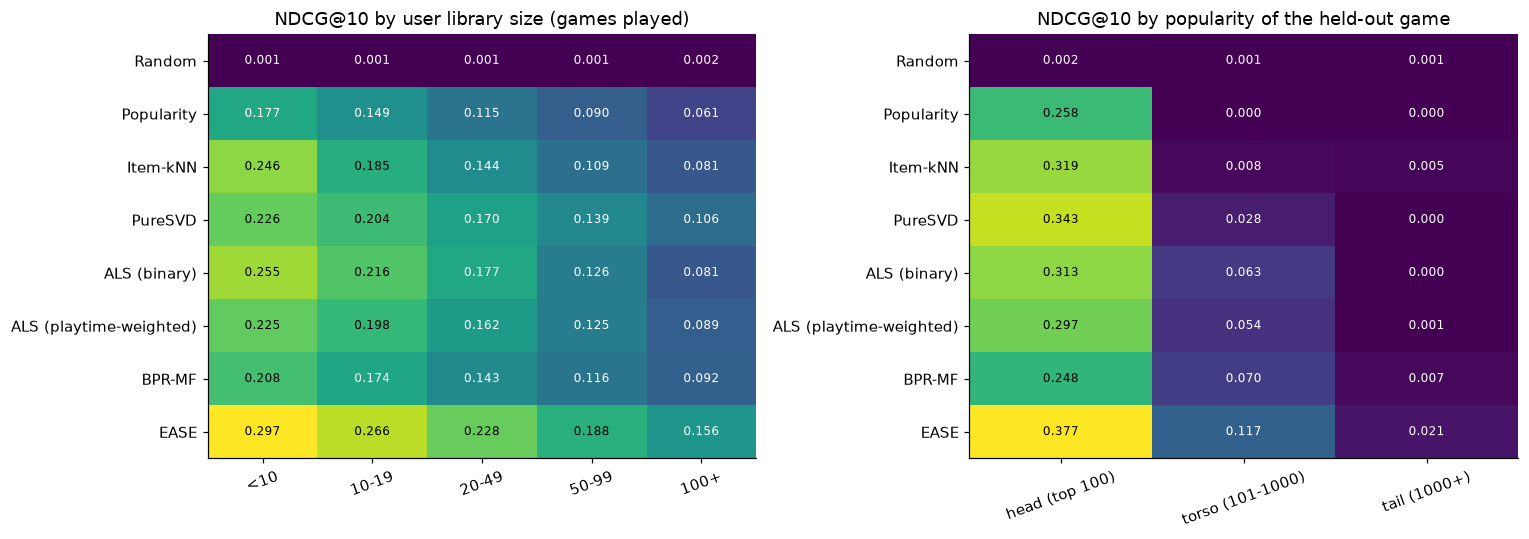

Share of test users per library-size bucket:
 {'<10': 0.134, '10-19': 0.173, '20-49': 0.33, '50-99': 0.233, '100+': 0.13}
Share of test games per popularity bucket:
 {'head (top 100)': 0.452, 'torso (101-1000)': 0.448, 'tail (1000+)': 0.1}


In [10]:
ucount = np.diff(X_trval.indptr)
ub = pd.cut(ucount, [0, 10, 20, 50, 100, np.inf], right=False, labels=["<10", "10-19", "20-49", "50-99", "100+"])
item_pop = np.asarray(X_trval.sum(0)).ravel(); pop_rank = np.empty(n_items, int); pop_rank[np.argsort(-item_pop, kind="stable")] = np.arange(n_items)
ib = pd.cut(pop_rank[test_item], [-1, 99, 999, np.inf], labels=["head (top 100)", "torso (101-1000)", "tail (1000+)"])

def heat(ax, df, title):
    im = ax.imshow(df.values, aspect="auto", cmap="viridis"); lo, hi = np.nanmin(df.values), np.nanmax(df.values)
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels(df.columns, rotation=20); ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(df.index); ax.set_title(title); ax.grid(False)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.values[i, j]; ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="w" if (v - lo) < (hi - lo) * .6 else "k", fontsize=8)

by_user = pd.DataFrame({n: pd.Series(per_user[n]["NDCG"]).groupby(ub, observed=True).mean() for n in MODEL_ORDER}).T
by_item = pd.DataFrame({n: pd.Series(per_user[n]["NDCG"]).groupby(ib, observed=True).mean() for n in MODEL_ORDER}).T
fig, ax = plt.subplots(1, 2, figsize=(14, 5)); heat(ax[0], by_user, "NDCG@10 by user library size (games played)"); heat(ax[1], by_item, "NDCG@10 by popularity of the held-out game"); plt.tight_layout(); plt.show()
print("Share of test users per library-size bucket:\n", pd.Series(ub).value_counts(normalize=True).sort_index().round(3).to_dict())
print("Share of test games per popularity bucket:\n", pd.Series(ib).value_counts(normalize=True).sort_index().round(3).to_dict())

## 4.5 Beyond accuracy: coverage and exposure
A recommender that only ever shows the 10 biggest games can score well on accuracy and still be useless for discovery. On a sample of up to 10,000 users we measure, for the top-10 lists:
- **Catalog coverage:** fraction of games recommended to at least one user.
- **Exposure Gini:** inequality of how often each game is recommended (0 = uniform, 1 = one game gets everything).
- **Mean popularity percentile** of recommended games (lower = more adventurous).

,Model,Coverage@10,Exposure Gini,Mean popularity percentile of recs,NDCG@10
0,Random,1.000,0.107,0.506,0.001
1,Popularity,0.019,0.995,0.003,0.116
2,Item-kNN,0.099,0.992,0.009,0.148
3,PureSVD,0.092,0.978,0.013,0.168
4,ALS (binary),0.234,0.957,0.023,0.170
5,ALS (playtime-weighted),0.187,0.963,0.021,0.159
6,BPR-MF,0.362,0.931,0.048,0.144
7,EASE,0.310,0.958,0.025,0.225


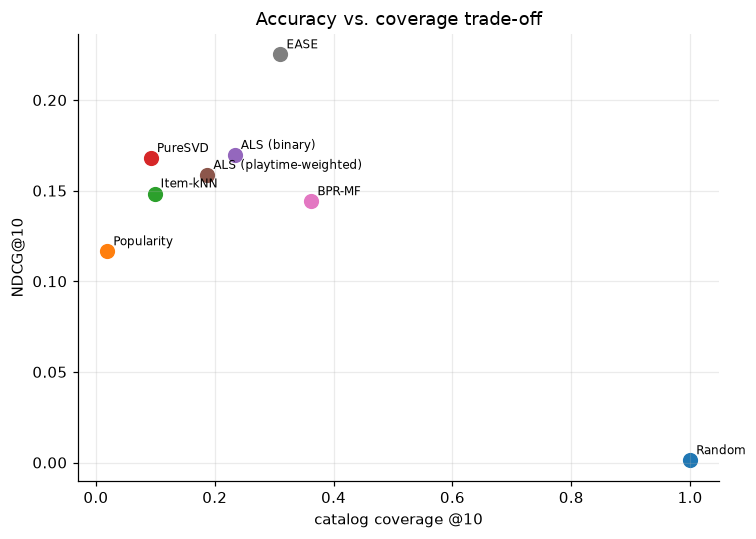

In [11]:
samp = rng.choice(n_users, min(10000, n_users), replace=False); pop_pct = pop_rank / n_items
rows = []
for n in MODEL_ORDER:
    recs = recommend(final_models[n], X_trval, samp); cnt = np.bincount(recs.ravel(), minlength=n_items)
    rows.append({"Model": n, "Coverage@10": (cnt > 0).mean(), "Exposure Gini": gini(cnt), "Mean popularity percentile of recs": pop_pct[recs].mean(), f"NDCG@{TOP_K}": per_user[n]["NDCG"].mean()})
beyond = pd.DataFrame(rows); display(beyond.style.format({c: "{:.3f}" for c in beyond.columns if c != "Model"}))

fig, ax = plt.subplots(figsize=(7, 5))
for _, r in beyond.iterrows():
    ax.scatter(r["Coverage@10"], r[f"NDCG@{TOP_K}"], s=80); ax.annotate(r["Model"], (r["Coverage@10"], r[f"NDCG@{TOP_K}"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="catalog coverage @10", ylabel=f"NDCG@{TOP_K}", title="Accuracy vs. coverage trade-off"); plt.tight_layout(); plt.show()

## 4.6 Qualitative checks: do the learned representations make sense?
Numbers can look good for the wrong reasons, so we also inspect (a) nearest-neighbor games under the ALS item factors and the Item-kNN similarity, (b) a t-SNE map of the 500 most-played games' ALS embeddings, and (c) one real user's recommendations.

,query game,ALS neighbours,Item-kNN neighbours
0,Portal 2,Left 4 Dead 2; Terraria; Garry's Mod; Counter-Strike: Source; Counter-Strike: Global Offensive,Garry's Mod; Portal; Left 4 Dead 2; Counter-Strike: Global Offensive; Terraria
1,Counter-Strike: Global Offensive,Garry's Mod; Left 4 Dead 2; Terraria; PAYDAY 2; Unturned,Garry's Mod; Left 4 Dead 2; Unturned; Terraria; PAYDAY 2
2,The Elder Scrolls V: Skyrim,Borderlands 2; Portal 2; Terraria; PAYDAY 2; Left 4 Dead 2,Terraria; Garry's Mod; Counter-Strike: Global Offensive; Borderlands 2; Fallout: New Vegas
3,Left 4 Dead 2,Counter-Strike: Global Offensive; Garry's Mod; Terraria; PAYDAY 2; Portal 2,Counter-Strike: Global Offensive; Garry's Mod; PAYDAY 2; Terraria; Unturned


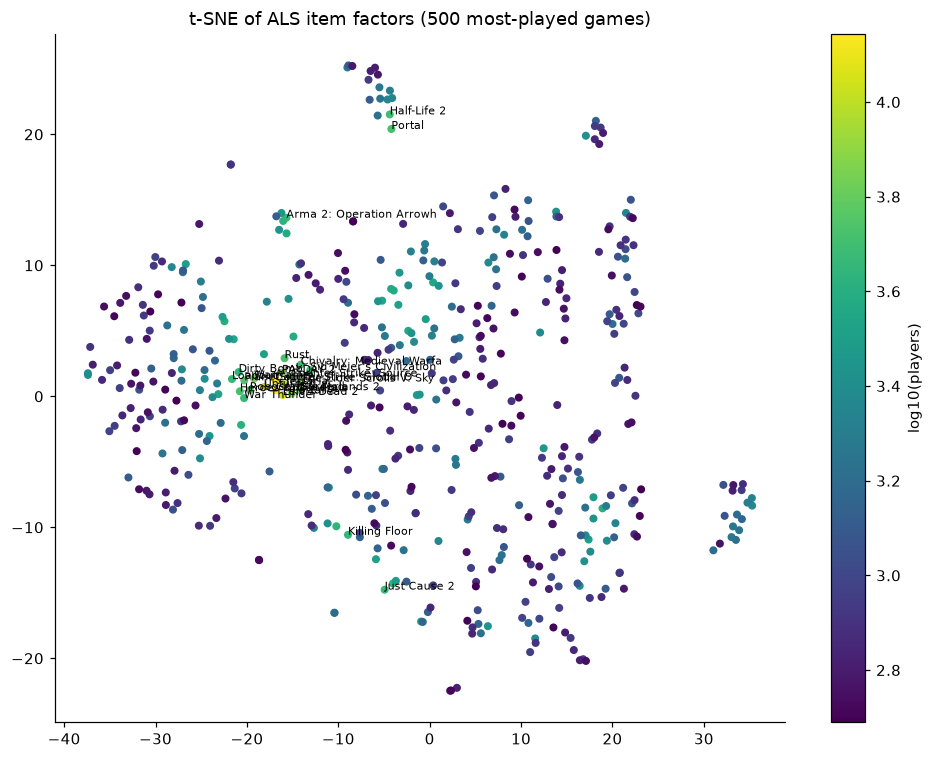

In [12]:
als = final_models["ALS (binary)"]; knn = final_models["Item-kNN"]
Yn = normalize(als.Y)
def neighbours(i, k=5):
    a = np.argsort(-(Yn @ Yn[i]))[1:k + 1]
    s = knn.S[i].toarray().ravel(); b = np.argsort(-s)[:k]
    return a, b
wanted = ["Portal 2", "Counter-Strike: Global Offensive", "The Elder Scrolls V: Skyrim", "Left 4 Dead 2", "Dota 2"]
q = [int(np.flatnonzero(item_names == w)[0]) for w in wanted if (item_names == w).any()]
if len(q) < 3: q = list(np.argsort(-item_pop)[:5])             # fallback: most popular games
rows = []
for i in q:
    a, b = neighbours(i); rows.append({"query game": item_names[i], "ALS neighbours": "; ".join(item_names[a]), "Item-kNN neighbours": "; ".join(item_names[b])})
pd.set_option("display.max_colwidth", 200); display(pd.DataFrame(rows))

top500 = np.argsort(-item_pop)[:500]
xy = TSNE(2, perplexity=30, random_state=SEED, init="pca").fit_transform(Yn[top500])
fig, ax = plt.subplots(figsize=(9, 7)); sc = ax.scatter(xy[:, 0], xy[:, 1], c=np.log10(item_pop[top500] + 1), cmap="viridis", s=18)
for j in range(25): ax.annotate(item_names[top500[j]][:24], xy[j], fontsize=7)
fig.colorbar(sc, label="log10(players)"); ax.set_title("t-SNE of ALS item factors (500 most-played games)"); ax.grid(False); plt.tight_layout(); plt.show()

In [13]:
# Case study: one real user (>= 30 played games whose held-out game the best model ranks in the top 10, if any)
cands = np.flatnonzero((ucount >= 30) & (per_user[best]["rank"] <= TOP_K)); u = int(cands[0]) if len(cands) else int(np.argmax(ucount))
history = trval[trval.u == u].sort_values("hours", ascending=False)
print(f"User #{u} | {ucount[u]} played games | held-out test game: {item_names[test_item[u]]}")
print("Most-played games:", "; ".join(f"{item_names[i][:28]} ({h:.0f}h)" for i, h in zip(history.i[:6], history.hours[:6])))
cs = []
for n in ["Popularity", "ALS (binary)", best] if best not in ("Popularity", "ALS (binary)") else ["Popularity", "ALS (binary)"]:
    rec = recommend(final_models[n], X_trval, np.array([u]))[0]
    print(f"\n{n}  (held-out game ranked #{per_user[n]['rank'][u]} of {ncand_test[u]})")
    for r, i in enumerate(rec, 1): print(f"  {r:2d}. {item_names[i]}" + ("   <-- HELD-OUT GAME" if i == test_item[u] else ""))

User #0 | 371 played games | held-out test game: Deus Ex: Human Revolution
Most-played games: Counter-Strike: Global Offen (330h); Borderlands 2 (189h); Call of Duty: Black Ops III (187h); Left 4 Dead 2 (154h); PAYDAY 2 (152h); Fallout: New Vegas (106h)

Popularity  (held-out game ranked #64 of 3199)
   1. Robocraft
   2. PlanetSide 2
   3. Heroes & Generals
   4. Chivalry: Medieval Warfare
   5. War Thunder
   6. Trove
   7. Realm of the Mad God
   8. Tom Clancy's Ghost Recon Phantoms - NA
   9. Starbound
  10. Brawlhalla

ALS (binary)  (held-out game ranked #10 of 3199)
   1. Left 4 Dead
   2. Deus Ex: Game of the Year Edition
   3. Mark of the Ninja
   4. Call of Duty: Modern Warfare 2 - Multiplayer
   5. METAL GEAR SOLID V: THE PHANTOM PAIN
   6. Tom Clancy's Splinter Cell: Conviction
   7. Call of Duty: Modern Warfare 2
   8. Call of Duty 4: Modern Warfare
   9. Tom Clancy's Ghost Recon Phantoms - NA
  10. Deus Ex: Human Revolution   <-- HELD-OUT GAME

EASE  (held-out game ranked 

# 5. Related work, conclusions, and limitations

## 5.1 Related work
**This dataset.** The UCSD Steam collection was introduced in work on sequential and bundle recommendation, and the dataset page lists:
- Kang & McAuley, *Self-attentive sequential recommendation* (ICDM 2018). Uses Steam among its benchmarks and models the *order* of a user's interactions.
- Wan & McAuley, *Item recommendation on monotonic behavior chains* (RecSys 2018). Uses chains of behaviors (e.g. view, then purchase).
- Pathak, Gupta & McAuley, *Generating and personalizing bundle recommendations on Steam* (SIGIR 2017). Bundles and personalization.
- The Australian profile crawl comes from O'Neill et al., *Condensing Steam: distilling the diversity of gamer behavior* (IMC 2016), as credited on the dataset page.

**Methods we implement.** Hu, Koren & Volinsky (ICDM 2008) for implicit ALS; Rendle et al. (UAI 2009) for BPR; Cremonesi, Koren & Turrin (RecSys 2010) for PureSVD on top-N tasks; Steck (WWW 2019) for EASE.

**Evaluation methodology.** Krichene & Rendle (KDD 2020) show that *sampled* metrics can reorder models, which is why we rank against the full catalog. Dacrema et al. (RecSys 2019) show that carefully tuned simple baselines often match or beat more complex neural methods, which is why we tune every baseline with the same budget and use bootstrap CIs.

**How our setting differs from prior Steam work.** Sequential models (SASRec and relatives) need timestamps and typically evaluate leave-last-out on *reviews*. This file has **no timestamps** and records **playtime**, so we use a random per-user holdout and a "played" signal. **Absolute numbers are therefore not comparable to published Steam results**; only the *relative ordering of methods* can be compared. *(Please re-check citation details against the originals before submitting.)*

## 5.2 Conclusions

In [14]:
tbl = results.set_index("Model"); base = "Popularity"
d_best = per_user[best]["NDCG"].mean() - per_user[base]["NDCG"].mean(); lo, hi = ci(boot[best]["NDCG"] - boot[base]["NDCG"])
order = tbl[f"NDCG@{TOP_K}"].sort_values(ascending=False)
rand_hr = np.mean(TOP_K / ncand_test)
bu = by_user.loc[[best, base]]; bi = by_item.loc[[best, base]]
cov = beyond.set_index("Model")["Coverage@10"]
display(Markdown(f'''
**Headline result (test set, {n_users:,} users, {n_items:,} games).**
- **{best}** is best on NDCG@{TOP_K} ({order.iloc[0]:.4f}); ranking of models: {" > ".join(f"{k} ({v:.4f})" for k, v in order.items())}.
- Versus Popularity: ΔNDCG@{TOP_K} = **{d_best:+.4f}** (95% paired-bootstrap CI [{lo:+.4f}, {hi:+.4f}]), a relative change of **{d_best / per_user[base]["NDCG"].mean():+.0%}**.
- Sanity check: Random HR@{TOP_K} = {tbl.loc["Random", f"HR@{TOP_K}"]:.4f} vs. theoretical {rand_hr:.4f}.
- Coverage@{TOP_K}: Popularity {cov["Popularity"]:.1%} vs. {best} {cov[best]:.1%}.
- On *tail* held-out games, NDCG@{TOP_K} is {bi.loc[best].iloc[-1]:.4f} for {best} vs. {bi.loc[base].iloc[-1]:.4f} for Popularity; on *head* games it is {bi.loc[best].iloc[0]:.4f} vs. {bi.loc[base].iloc[0]:.4f}.
- Playtime weighting in ALS: {tbl.loc["ALS (playtime-weighted)", f"NDCG@{TOP_K}"]:.4f} (weighted) vs. {tbl.loc["ALS (binary)", f"NDCG@{TOP_K}"]:.4f} (binary).
'''))


**Headline result (test set, 20,940 users, 3,570 games).**
- **EASE** is best on NDCG@10 (0.2251); ranking of models: EASE (0.2251) > ALS (binary) (0.1696) > PureSVD (0.1679) > ALS (playtime-weighted) (0.1586) > Item-kNN (0.1484) > BPR-MF (0.1441) > Popularity (0.1165) > Random (0.0012).
- Versus Popularity: ΔNDCG@10 = **+0.1087** (95% paired-bootstrap CI [+0.1047, +0.1130]), a relative change of **+93%**.
- Sanity check: Random HR@10 = 0.0027 vs. theoretical 0.0028.
- Coverage@10: Popularity 1.9% vs. EASE 31.0%.
- On *tail* held-out games, NDCG@10 is 0.0211 for EASE vs. 0.0000 for Popularity; on *head* games it is 0.3771 vs. 0.2578.
- Playtime weighting in ALS: 0.1586 (weighted) vs. 0.1696 (binary).


**Interpreting the numbers.** Compare the paired-difference table (does the CI exclude 0?), the stratified heat-maps (where do personalized models help?), and the coverage table (is accuracy bought with diversity?). Negative or surprising results (for example a tuned neighborhood method matching a factor model, or weighting not helping) should be explained by reference to these, not hidden.

## 5.3 Limitations and validity threats
- **Offline proxy.** A held-out *played* game is not a verified preference; a user may play many games they dislike, and may like games they never discovered (exposure bias).
- **Random, not temporal, split.** No timestamps are available, so models may see "future" games of the same user. Absolute scores will be optimistic compared with a deployed next-game system.
- **Single split / single seed.** Bootstrap CIs capture *user* sampling noise, not split noise. A repeated-split study would be stronger.
- **Sampling.** Results are for a random `SAMPLE_FRAC` of the users and the k-core-filtered catalog; cold-start games (below `MIN_ITEM_USERS`) and cold-start users are out of scope.
- **Popularity bias in evaluation.** Random per-user holdout favors popular games as targets; the head/torso/tail breakdown is there to expose this.
- **Scalability.** EASE and the dense Item-kNN Gram matrix need $O(I^2)$ memory and would not scale to millions of items.

## 5.4 Future work
Time-aware split using review timestamps, content features (genres, tags) for cold-start games, hybrid models blending EASE and ALS scores, sequence models (SASRec), and bundle-aware recommendation.